# Section 5.1: an $\mathrm{SO}(2)$-equivariant flow on $S^2$

This notebook regenerates every number that Section 5.1 of the paper and its appendix state for the sphere example, and every panel of the figures `fig:sphere-computation`, `fig:sphere-reconstruction`, `fig:appendix-sphere-height` and `fig:appendix-sphere-comparison`. Each code cell calls functions of `morsegraphs/so2_flow.py` or `morsegraphs/plotting.py` and shows one table, one line or one figure.

The vector field $V(p)=0.6\,e_3\times p+z(0.4^2-z^2)(e_3-zp)$ on $X=S^2$, with $z=p\cdot e_3$, is equivariant under the rotations $G=\mathrm{SO}(2)$ about $e_3$, and $F$ is its time-ten map. The height $z$ identifies $X/G$ with $[-1,1]$ and the quotient map with the time-ten map $h_{10}$ of the flow $h_s$ of $\dot z=z(0.4^2-z^2)(1-z^2)$, so the poles $\pm e_3$ and the equator $C$ repel and the latitudes $A_\pm=\{z=\pm0.4\}$ attract. Tables write a role and the name the text uses, such as `S (-e3)`; the graphs and the sphere panels write $S$ and $N$ for the poles $-e_3$ and $e_3$.

## Settings

This is the only cell to edit. With `MODE = "replay"` the notebook loads the selected fit of `data/ex1_so2_flow/models/` and checks every result against `data/ex1_so2_flow/reference/results.json`, stopping at a difference. With `MODE = "train"` it retrains the selected seed with `data/ex1_so2_flow/config.json` on the CPU, which adds about two minutes, compares the weights with the stored ones, and reports differences instead of stopping. With `OUT = None` the results go to a new folder under `outputs/notebooks/`. A replay takes about a minute. The device is set once per kernel, before JAX starts.

In [1]:
MODE = "replay"  # "replay": the selected fit; "train": retrain the selected seed with config.json
OUT = None       # None: a new folder under outputs/notebooks/

from morsegraphs import device
device.configure("float64", "cpu")
from morsegraphs import plotting, so2_flow

run = so2_flow.start(MODE, OUT)
run

Setting,Value
Mode,replay of the selected fit
Selected fit,"seed0, lowest validation objective (data/ex1_so2_flow/selection.json)"
Grid,"2^7 cells of [-1, 1]"
Map of the Morse graph,"f^10, for the learned time-one map f"
Image hulls,"65 samples per cell, padding 1e-10"
Output folder,outputs/notebooks/ex1_so2_flow-replay-20261114-010211


## The system and the reference quotient map

The function $Q(z)=w^{21}(1-w)^4/|w-4/25|^{25}$, $w=z^2$, satisfies $Q(h_t(z))=e^{168t/25}Q(z)$ away from the fixed heights. Bisection on $Q$ in exact rational arithmetic gives an enclosure of $h_{10}$ at every binary64 height, and since $h_{10}$ is increasing, the cell $[a,b]$ maps into the interval from the lower end of the enclosure at $a$ to the upper end at $b$. The table checks the equivariance of $V$ on samples, the height derivative at $z=1/2$ that the appendix quotes, and the width of the enclosures.

In [2]:
so2_flow.system_table()

Check,Value
"Equivariance of V: max |V(R p) - R V(p)| over 1,000 points and 3 rotations",2.22e-16
Height rate z(0.4^2 - z^2)(1 - z^2) at z = 1/2,-0.03375
Widest enclosure of h_10 at the 129 cell boundaries of the grid,3.33e-14
"h_10 fixes -1, 0 and 1 exactly",yes


## Reference Morse graph

On the uniform grid of $2^7$ cells of $[-1,1]$, CMGDB computes the outer approximation of $h_{10}$ from these enclosures, its Morse sets, the Morse graph and the Conley index of each Morse set over $\mathbb F_5$. An annotation lists the index map in degrees 0 and 1 by its shift class: `x-1` is $\mathbb F_5$ with the identity map and `0` the zero group. Each Morse set is named by the reference invariant set whose height lies in its cells.

In [3]:
reference = so2_flow.reference_graph(run.settings)
so2_flow.graph_table(reference, "z", "Reference Morse graph of h_10")

Morse set,Role,Cells,Interval in z,Conley index,Edges to
1,S (-e3),0,"[-1, -0.984375]","(0, 0)",0 (A-)
0,A-,38,"[-0.40625, -0.390625]","(x-1, 0)",none
3,C,"63, 64","[-0.015625, 0.015625]","(0, x-1)","0 (A-), 2 (A+)"
2,A+,89,"[0.390625, 0.40625]","(x-1, 0)",none
4,N (e3),127,"[0.984375, 1]","(0, 0)",2 (A+)


## Data

The training data are pairs $(p,F_1(p))$, with $F_1$ the time-one map. In each split, three quarters of the starting heights are uniform in $[-1,1]$ and a quarter lie near the poles, with $\log_{10}(1-|z|)$ uniform in $[-10,-2]$; the longitudes are uniform. The heights are integrated in the coordinate $\operatorname{arctanh}(z)$ with DOP853. The states at time 10 serve only the held-out errors. The arrays are checked against the checksums recorded with them.

In [4]:
data = so2_flow.load_data(run.data)
so2_flow.data_table(data, run.data)

Split,Starts,Share within 0.01 of a pole,Times
train,16384,0.258,"0, 1, 10"
validation,4096,0.258,"0, 1, 10"
test,4096,0.258,"0, 1, 10"


## Fits and selection

The invariant encoder $E\colon S^2\to[-1,1]$, the orbit decoder $d$ and the time-one map $f$ of $[-1,1]$ are EMLP networks with two hidden layers of 32 scalar channels. With $M(u,s)=(u+\tanh s)/(1+u\tanh s)$, which fixes $\pm1$, the decoder is $d(u)=M(u,0.35\tanh a(u))$ and the map is $f(u)=M(u,1.4\tanh b(u))$. The encoder is an invariant network $\eta=\tanh e$ calibrated so that the poles, the points fixed by $G$, go to the ends: $E(p)=2(\eta(p)-\eta(-e_3))/(\eta(e_3)-\eta(-e_3))-1$. The objective sums the orbit reconstruction of $d(E(p))$, the orbit prediction of $d(f(E(p)))$ against $F_1(p)$ and the consistency of $f(E(p))$ with $E(F_1(p))$, each with a term in the log latitude, and a penalty that keeps $E$ increasing along a meridian (`so2_flow.objective`). Five seeds were trained with 20,000 Adam updates each, and the fit with the lowest validation objective is selected before any CMGDB computation. All five fits are kept in `data/ex1_so2_flow/models/`, since the paper reports the outcome of the selected fit, not of every fit.

In [5]:
so2_flow.seeds_table(run)

Rank,Fit,Validation objective,Selected step,One-step orbit RMS,Ten-step orbit RMS,E increasing,Least slope of E,Fixed points of f
1,seed0 (selected),3.943e-05,20000,0.004299,0.01382,yes,0.573,5
2,seed2,5.31e-05,19800,0.004943,0.01617,yes,0.571,5
3,seed1,0.0003261,20000,0.01209,0.06707,yes,0.686,5
4,seed3,0.0003782,19900,0.01281,0.0712,yes,0.608,5
5,seed4,0.0004305,19900,0.01321,0.07272,yes,0.561,5


The selected fit. In replay its weights are loaded. In train mode the same seed is trained again with the same data and settings, and its weights are compared with the stored ones.

In [6]:
model, fit = so2_flow.selected_fit(run, data)
fit

Loaded seed0 from data/ex1_so2_flow/models/seed0: selected at step 20,000 with validation objective 3.94312e-05; weights digest 2adee0ce6f9f6d1e.

## Held-out errors

On the 4,096 starts of the test split, the decoded prediction $d(f^h(E(p)))$ is compared with the orbit of the state at time $h$, in the chordal distance between circles of latitude. Section 5.1 quotes the ten-step root-mean-square error. The other rows are sampled checks: the invariance of $E$, that $E$ and $f$ increase, the residual $|f^{10}(E(p))-E(F(p))|$ on the test starts, and the heights whose codes are the fixed points of $f$.

In [7]:
metrics = so2_flow.diagnostics(model, data)
so2_flow.diagnostics_table(metrics)

Quantity,Orbit or value,Height RMS,Height maximum
Orbit RMS of d(f^0(E(p))) against the orbit at time 0,0.0004688,0.0003947,0.0007529
Orbit RMS of d(f^1(E(p))) against the orbit at time 1,0.004299,0.002895,0.009728
Orbit RMS of d(f^10(E(p))) against the orbit at time 10,0.01382,0.01002,0.04141
"Invariance of E: max |E(R p) - E(p)|, 3 rotations",0,,
E increasing along a meridian; least slope,yes,0.573,
f increasing; least slope,yes,0.646,
Residual |f^10(E(p)) - E(F(p))|: RMS and maximum on the test starts,0.0102,0.04233,
Heights z with E(p_z) a fixed point of f,"-1.0000, -0.4000, -0.0081, 0.3944, 1.0000",,


## Learned Morse graph, raw and merged

CMGDB computes the Morse graph of $f^{10}$ on the same grid of $2^7$ cells of $[-1,1]$, now in the learned coordinate $u$. The image of each cell is the hull of the images of 65 equally spaced points of the cell, its ends included, padded by $10^{-10}$ and cut at $\pm1$, which $f$ fixes. These hulls are sampled, not validated enclosures. A Morse set takes the role of the reference invariant set whose code, $E$ of its latitude, is nearest to its cells, provided all its cells lie within four cells of that code.

In [8]:
raw, merged = so2_flow.learned_graph(model, run.settings)
so2_flow.graph_table(raw, "u", "Raw Morse graph of f^10")

Morse set,Role,Cells,Interval in u,Conley index,Edges to
1,S (-e3),0,"[-1, -0.984375]","(0, 0)",0 (A-)
0,A-,25,"[-0.609375, -0.59375]","(x-1, 0)",none
2,C,46,"[-0.28125, -0.265625]","(0, 0)",0 (A-)
4,C,47,"[-0.265625, -0.25]","(0, x-1)","2 (C), 3 (A+)"
3,A+,74,"[0.15625, 0.171875]","(x-1, 0)",none
5,N (e3),127,"[0.984375, 1]","(0, 0)",3 (A+)


The raw graph has a Morse set of one cell with trivial index next to the Morse set at $C$, and both take the role $C$. As the example prescribes, the Morse sets of one role are merged with all cells on paths between them, the group is checked to be order convex, and CMGDB recomputes the Conley index of the merged set. The role, not the trivial index, decides the merge. The raw graph is kept for verification.

In [9]:
so2_flow.graph_table(merged, "u", "Merged Morse graph of f^10")

Morse set,Role,Merged Morse sets,Cells,Interval in u,Conley index,Edges to
1,S (-e3),1,0,"[-1, -0.984375]","(0, 0)",0 (A-)
0,A-,0,25,"[-0.609375, -0.59375]","(x-1, 0)",none
2,C,"2, 4","46, 47","[-0.28125, -0.25]","(0, x-1)","0 (A-), 3 (A+)"
3,A+,3,74,"[0.15625, 0.171875]","(x-1, 0)",none
4,N (e3),5,127,"[0.984375, 1]","(0, 0)",3 (A+)


## Comparison with the reference

The learned nodes take the labels of the reference only where the graphs agree: the same roles, the same Conley index in $[-1,1]$ at each role, and the same edges between roles.

In [10]:
comparison = so2_flow.compare_graphs(reference, merged)
so2_flow.comparison_table(comparison)

Role,Reference cells,Reference index,Learned cells,Raw Morse sets,Learned index,Agree
S (-e3),0,"(0, 0)",0,1,"(0, 0)",yes
A-,38,"(x-1, 0)",25,0,"(x-1, 0)",yes
C,"63, 64","(0, x-1)","46, 47","2, 4","(0, x-1)",yes
A+,89,"(x-1, 0)",74,3,"(x-1, 0)",yes
N (e3),127,"(0, 0)",127,5,"(0, 0)",yes
Order,"-e3 -> A-, C -> A-, C -> A+, e3 -> A+",,"-e3 -> A-, C -> A-, C -> A+, e3 -> A+",,,yes


## Attracting regions, tolerances and residuals modulo $G$

For each minimal Morse set $\mathcal M$, $\mathcal A$ is the set of cells from which no path of the outer approximation leaves the box or reaches a Morse set outside $\mathcal M$, and $N=|\mathcal A|$. The ends $\pm1$ are faces of the orbit space, not exits. The tolerance of $N$ is the distance from the image hulls of the cells of $\mathcal A$ to the complement of $N$. The residual modulo $G$ of $f^{10}$ at $p$ is $|f^{10}(E(p))-E(F(p))|$; it is constant on orbits, and every orbit meets a meridian, so its maximum over $E^{-1}(N)$ is sampled on 69,537 points of one meridian, refined near the poles. A residual below the tolerance is the inequality of Proposition `prop:equivariant_pullback`(ii) for the sampled quantities, so $E^{-1}(N)$ is an observed, not proved, attracting block for $F$. The regions are computed on the raw graph; the merged graph has the same minimal Morse sets and gives the same regions.

In [11]:
rows, samples = so2_flow.attracting_regions(model, raw, run.settings)
so2_flow.regions_table(rows, raw)

Metric,Minimal Morse set,Cells of A,|A| in u,Samples in E^-1(N),Largest residual,Tolerance,Residual below tolerance
euclidean,A-,45,"[-0.984375, -0.28125]","27,326",0.01534,0.08059,yes
euclidean,A+,79,"[-0.25, 0.984375]","29,746",0.04234,0.05932,yes
chordal,A-,45,"[-0.984375, -0.28125]","27,326",0.01809,0.08512,yes
chordal,A+,79,"[-0.25, 0.984375]","29,746",0.04275,0.06082,yes


## Conley indices in $S^2$

Theorem `thm:sphere-reconstruction` gives the index map of the lifted index pair from quotient data. Here $P/G=\{-1,1\}$ (the poles), the orbits $G/H$ are circles ($m=1$) and the rotation of the orbits has degree 1, so the index in degree $k$ is the direct sum of the quotient index in degree $k$ and the index relative to $N_P/G$ in degree $k-1$. `morsegraphs.homology` evaluates it over $\mathbb F_5$ on the index pair $(|\mathcal M\cup F(\mathcal M)|,|F(\mathcal M)\setminus\mathcal M|)$ of each Morse set, with a chain selector that maps the poles to the poles, for the reference graph and for the merged learned graph. The indices proved on explicit index pairs (Supplement `supp:sphere-pairs`) are $H_2=\mathbb F$ at the poles, $H_1=H_2=\mathbb F$ at $C$ and $H_0=H_1=\mathbb F$ at $A_\pm$, with identity index maps. The reference reconstruction uses the enclosures of $h_{10}$. The learned one uses sampled hulls, so its indices in $S^2$ are observed.

In [12]:
indices = so2_flow.reconstructed_indices({"reference": reference, "learned": merged})
so2_flow.indices_table(indices)

Role,Proved in S^2,Nonzero groups,"Reference in [-1, 1]",Reference in S^2,"Learned in [-1, 1]",Learned in S^2,Agree
S (-e3),"(0, 0, x-1)",H_2 = F,"(0, 0)","(0, 0, x-1)","(0, 0)","(0, 0, x-1)",yes
A-,"(x-1, x-1, 0)",H_0 = H_1 = F,"(x-1, 0)","(x-1, x-1, 0)","(x-1, 0)","(x-1, x-1, 0)",yes
C,"(0, x-1, x-1)",H_1 = H_2 = F,"(0, x-1)","(0, x-1, x-1)","(0, x-1)","(0, x-1, x-1)",yes
A+,"(x-1, x-1, 0)",H_0 = H_1 = F,"(x-1, 0)","(x-1, x-1, 0)","(x-1, 0)","(x-1, x-1, 0)",yes
N (e3),"(0, 0, x-1)",H_2 = F,"(0, 0)","(0, 0, x-1)","(0, 0)","(0, 0, x-1)",yes


## Figures

Each panel is saved bare, with no letters, titles or legends, as PDF and SVG under `OUT/figures/`, with the file name the manuscript includes, and shown below under that name. A Morse set is colored by its role: the attractors $A_-$ blue and $A_+$ green, the repelling poles $S$ vermilion and $N$ orange, and the repelling equator $C$ purple. The physical height is $z$ and the learned coordinate $u$.

### `fig:sphere-computation`

(a) The learned height map $z\mapsto d(f^{10}(E(p_z)))$, with $p_z$ the point of height $z$ on a meridian. A fixed point is drawn in the color of the Morse set whose cells contain its code, filled where the slope is below one. (b) The merged Morse graph of $f^{10}$ in $[-1,1]$ with its Conley indices.

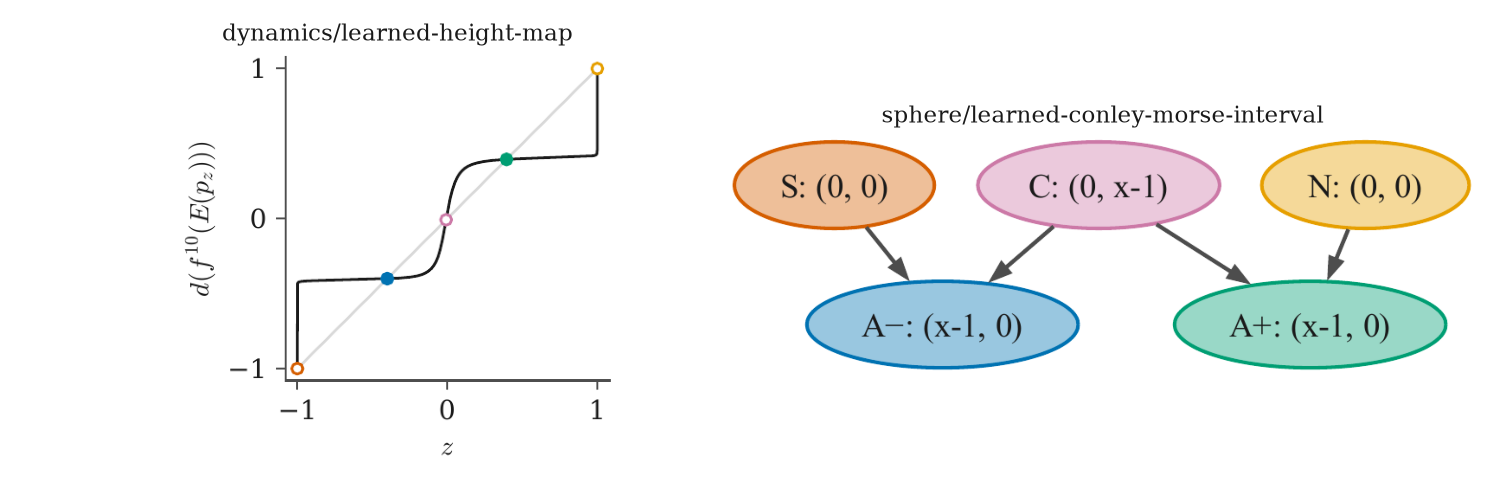

In [13]:
panels = so2_flow.figure_sphere_computation(model, merged, run.figures)
plotting.show(panels.values(), panels.keys())

### `fig:sphere-reconstruction`

(a) $E^{-1}(|\mathcal M|)$ in $S^2$: since $E$ increases along a meridian, the preimage of each cell is a band of latitude, whose boundary heights are found by inverting $E$ on a meridian. (b) The merged Morse graph with the indices in $S^2$ reconstructed above.

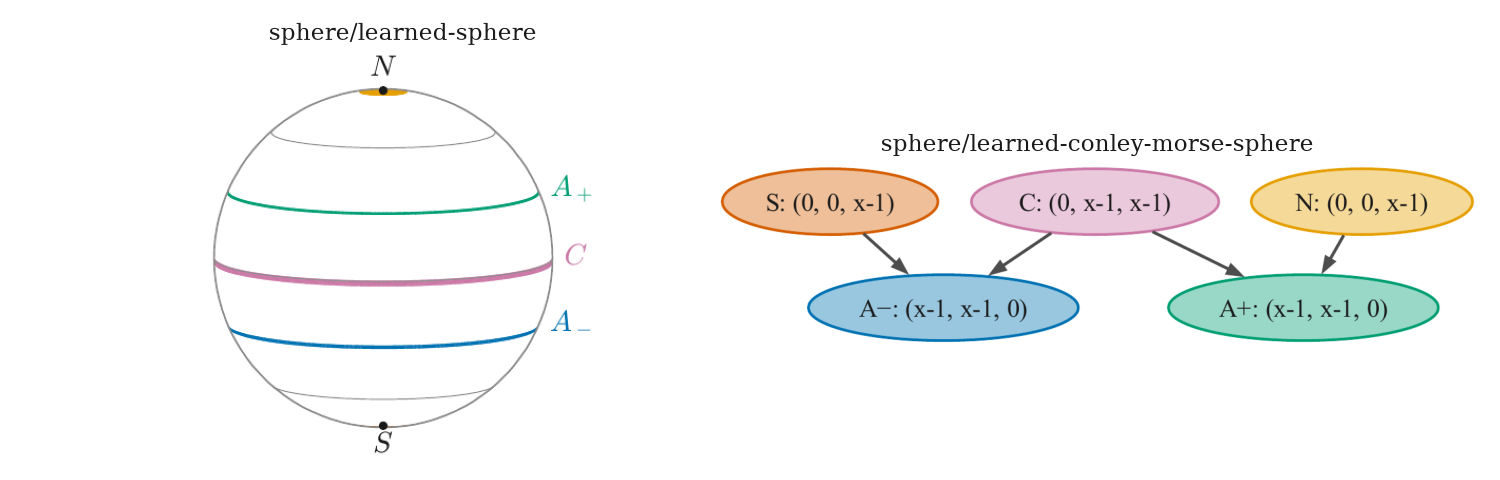

In [14]:
panels = so2_flow.figure_sphere_reconstruction(model, merged, indices, run.figures)
plotting.show(panels.values(), panels.keys())

### `fig:appendix-sphere-height`

(a) Six trajectories of $V$ for $0\le t\le18$, which turn at angular speed $0.6$, with their starting points and the direction of motion at $t=3$; the latitudes $A_-$, $C$ and $A_+$ are drawn in their colors. (b) The physical height map $h_3$, whose fixed heights are its intersections with the diagonal.

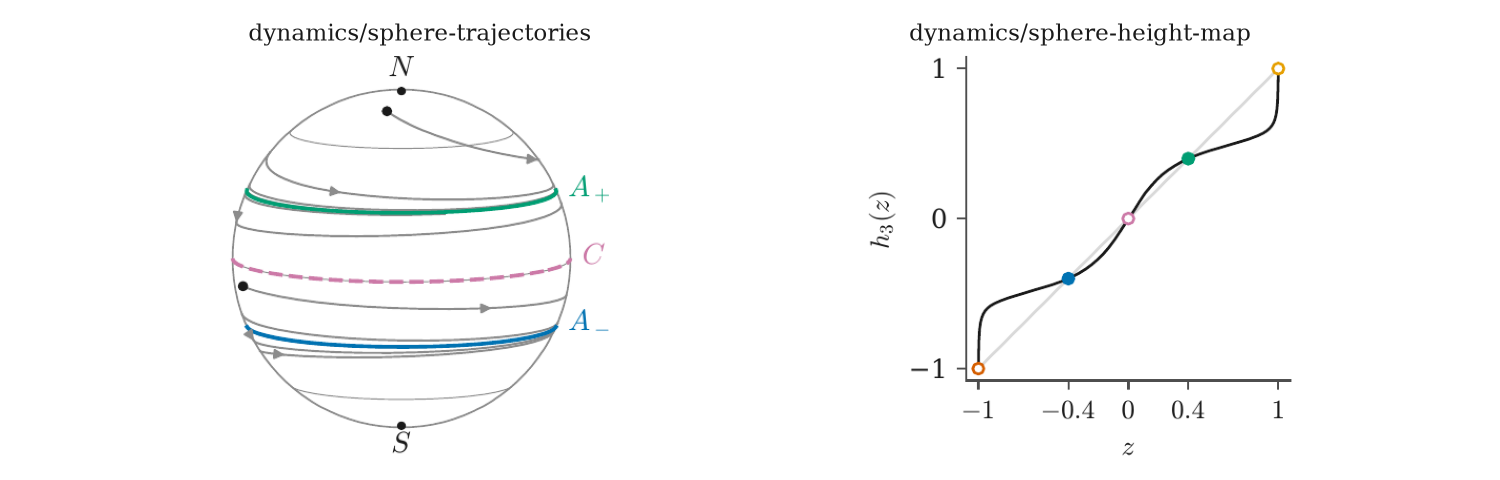

In [15]:
panels = so2_flow.figure_sphere_height(run.figures)
plotting.show(panels.values(), panels.keys())

### `fig:appendix-sphere-comparison`

The reference $h_{10}$ (left) and the learned $f^{10}$ (right). From the top: the preimages of the Morse sets on the sphere, the Morse cells in the interval, the Morse graphs with their Conley indices in $[-1,1]$, and the Morse graphs with the indices in $S^2$ reconstructed from them.

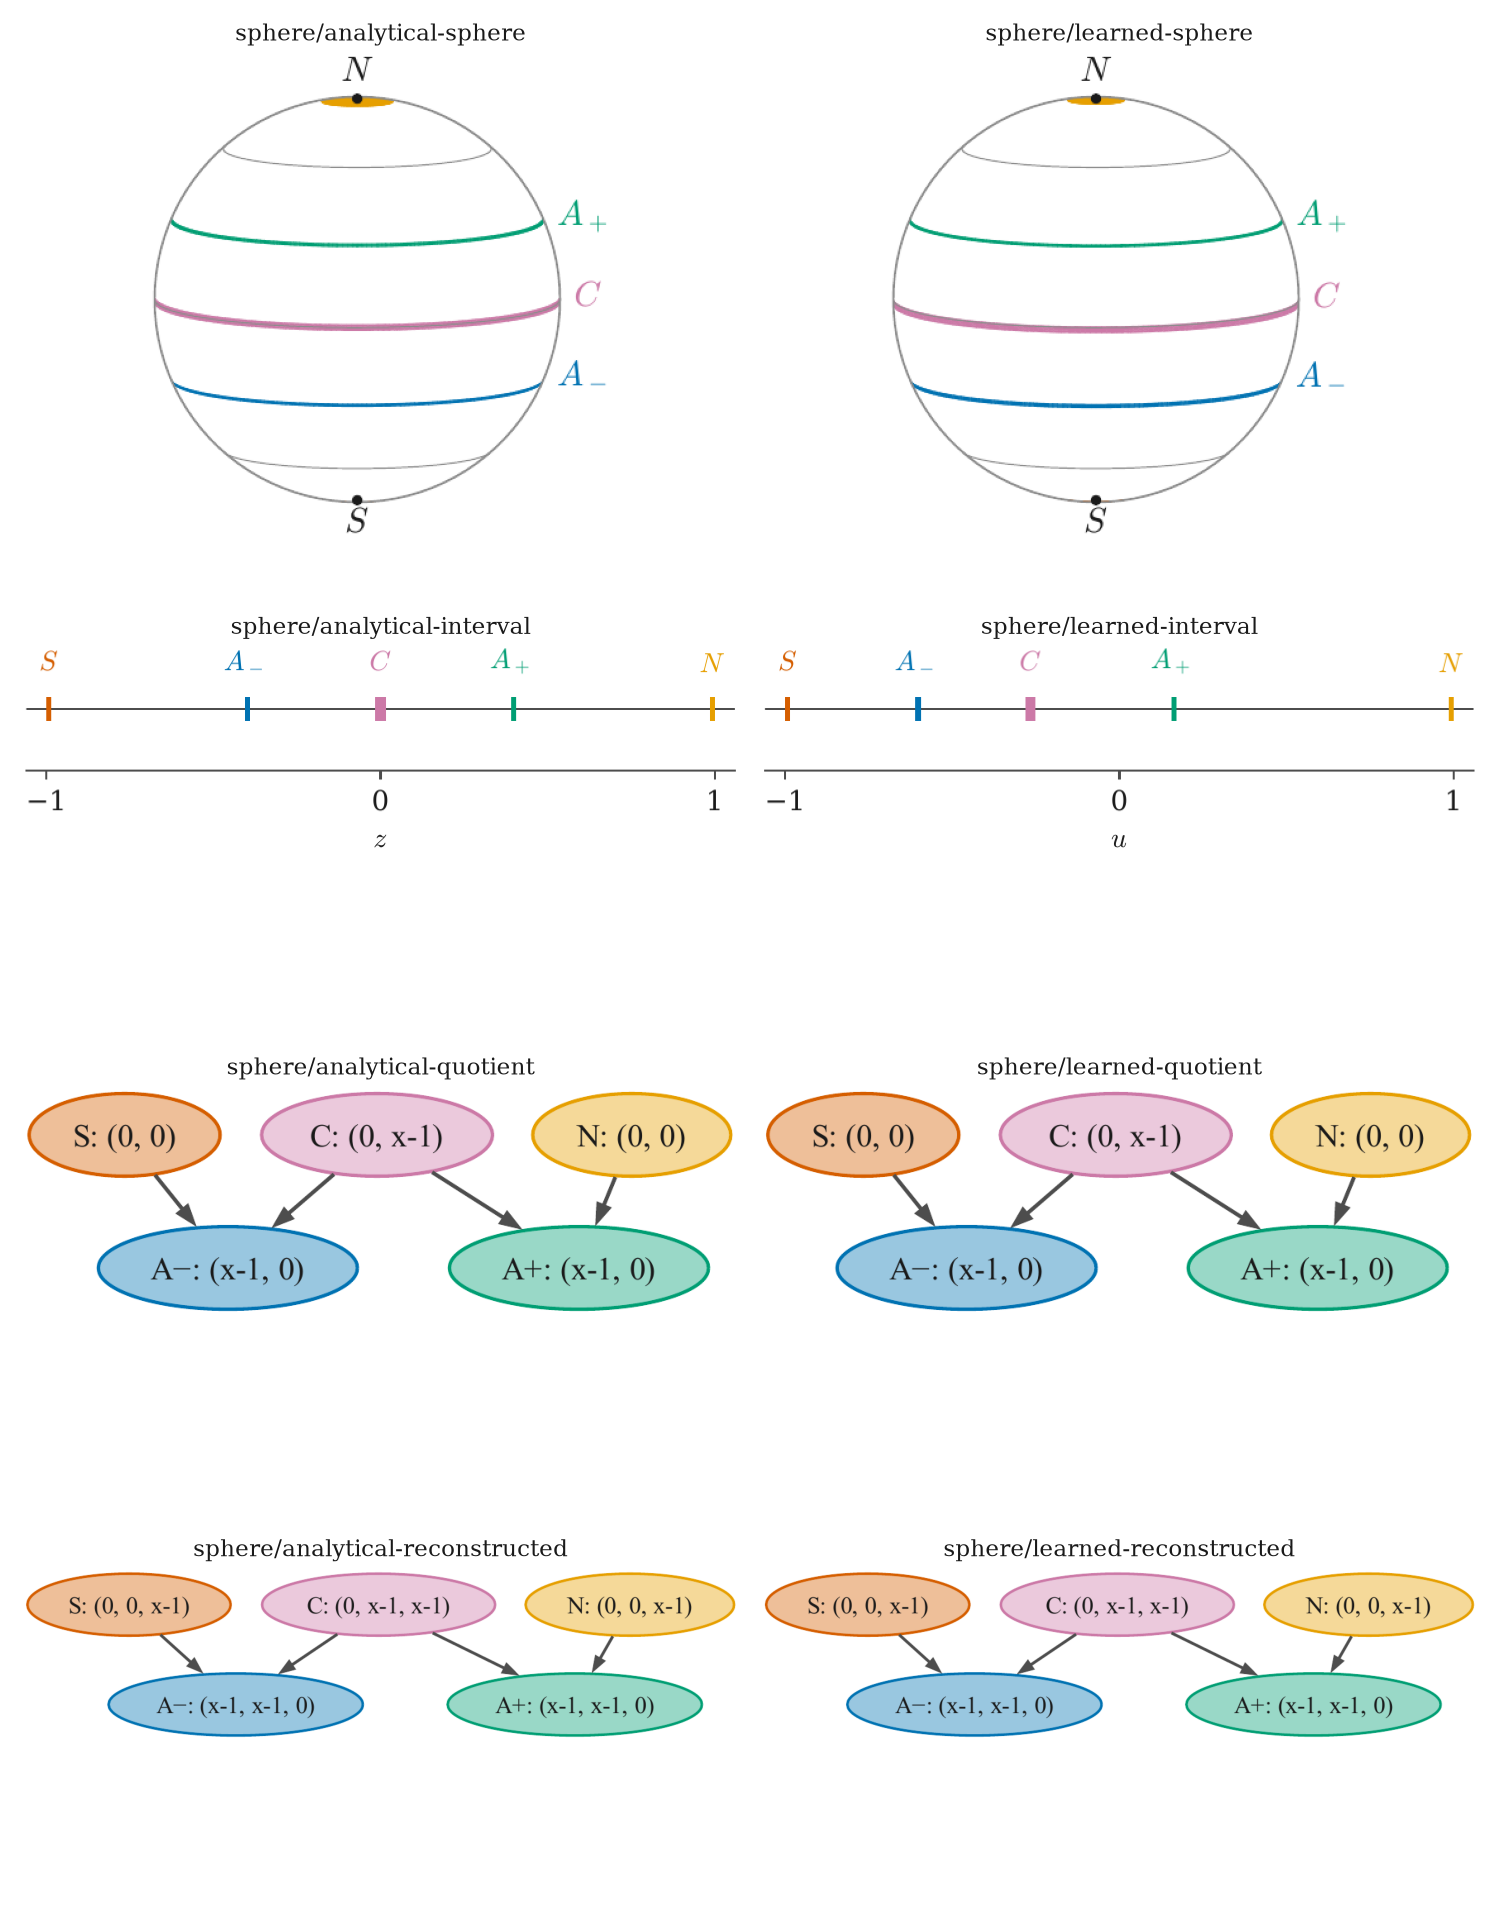

In [16]:
panels = so2_flow.figure_sphere_comparison(model, reference, merged, indices, run.figures)
plotting.show(panels.values(), panels.keys(), columns=2)

## Replay check

The record of the results above (the fit, the diagnostics, the reference, raw and merged graphs, the comparison, the regions with their tolerances and residuals, and the reconstructed indices) is written to `OUT/record.json` and compared with `data/ex1_so2_flow/reference/results.json`, which `scripts/record_reference.py ex1_so2_flow` writes: graphs and indices exactly, other numbers to relative tolerance $10^{-9}$. In replay a difference stops the notebook. In train mode it is reported.

In [17]:
record = so2_flow.record_of(run.fit, metrics, reference, raw, merged, rows, samples, indices)
check = so2_flow.check_record(run, record)
check

The record matches data/ex1_so2_flow/reference/results.json: 932 values, graphs and indices exactly, other numbers to relative 1e-9.

## Summary

Every quantity that Section 5.1 and its appendix state, computed here, next to the value in the current text of the manuscript. The text describes an earlier fit, so its values differ from those of the selected fit; the comparison is informational. The table is also written, with the replay check, the list of saved panels and the package versions, to `OUT/verification.json`.

In [18]:
so2_flow.summary(run, record, check)

Where,Statement,Manuscript,Computed
Section 5.1,Ten-step orbit RMS on held-out data,0.016,0.0138
Section 5.1,Morse graphs of f^10 and h_10 on 2^7 cells agree,agree,"agree after the prescribed merge (6 raw Morse sets, 5 merged)"
Section 5.1,Order,"-e3 -> A-, C -> A-, C -> A+, e3 -> A+","-e3 -> A-, C -> A-, C -> A+, e3 -> A+"
Section 5.1,"Conley indices in [-1, 1] match the reference",yes,yes
Section 5.1,A-: largest sampled residual of f^10 against the tolerance,0.026 < 0.036,0.0153 < 0.0806
Section 5.1,A+: largest sampled residual of f^10 against the tolerance,0.033 < 0.043,0.0423 < 0.0593
Section 5.1,"Indices in S^2: H_2 = F at the poles, H_1 = H_2 = F at C, H_0 = H_1 = F at A-+",proved; reconstruction agrees,reconstruction agrees for the reference and the learned graph
supp:sphere-walkthrough,Height derivative at z = 1/2,-0.03375,-0.03375
supp:sphere-computation,Cells of the two attracting regions,41 and 84,45 and 79
supp:sphere-computation,Meridian samples,"69,537","69,537"
